In [1]:

var('t')
a = function('a')(t)

diff(a, t, 2)



diff(a(t), t, t)

In [2]:

%display latex

var('t')
a = function('a')(t)

show(diff(a, t, 2))


diff(a(t), t, t)

In [3]:

%display latex

M = Manifold(4, 'M', structure='Lorentzian')
X.<t,r,th,ph> = M.chart(
    r't r:(0,+oo) th:(0,pi):\theta ph:(0,2*pi):\phi'
)

k = var('k')
a = M.scalar_field(function('a')(t), name='a')

g = M.metric()
g[0,0] = -1
g[1,1] = a*a/(1-k*r^2)
g[2,2] = a*a*r^2
g[3,3] = a*a*r^2*sin(th)^2

show(g[:])


[                  -1                    0                    0                    0]
[                   0  -a(t)^2/(k*r^2 - 1)                    0                    0]
[                   0                    0           r^2*a(t)^2                    0]
[                   0                    0                    0 r^2*a(t)^2*sin(th)^2]

In [4]:

g.christoffel_symbols_display()


Matplotlib is building the font cache; this may take a moment.


Gam^t_r,r = -a(t)*d(a)/dt/(k*r^2 - 1) 
Gam^t_th,th = r^2*a(t)*d(a)/dt 
Gam^t_ph,ph = r^2*a(t)*sin(th)^2*d(a)/dt 
Gam^r_t,r = d(a)/dt/a(t) 
Gam^r_r,r = -k*r/(k*r^2 - 1) 
Gam^r_th,th = k*r^3 - r 
Gam^r_ph,ph = (k*r^3 - r)*sin(th)^2 
Gam^th_t,th = d(a)/dt/a(t) 
Gam^th_r,th = 1/r 
Gam^th_ph,ph = -cos(th)*sin(th) 
Gam^ph_t,ph = d(a)/dt/a(t) 
Gam^ph_r,ph = 1/r 
Gam^ph_th,ph = cos(th)/sin(th)

In [5]:

# Ricci tensor
Ric = g.ricci()
show(Ric[:])

# Ricci scalar
R = g.ricci_scalar()
show(R.expr())



[                                           -3*d^2(a)/dt^2/a(t)                                                              0                                                              0                                                              0]
[                                                             0          -(2*(d(a)/dt)^2 + a(t)*d^2(a)/dt^2 + 2*k)/(k*r^2 - 1)                                                              0                                                              0]
[                                                             0                                                              0             2*r^2*(d(a)/dt)^2 + r^2*a(t)*d^2(a)/dt^2 + 2*k*r^2                                                              0]
[                                                             0                                                              0                                                              0 (2*r^2*(d(a)/dt)^2 + r^2*a(t)*d^2(a)/dt^2 + 2*k*r^2)*sin(th)^2]

6*(diff(a(t), t)^2 + a(t)*diff(a(t), t, t) + k)/a(t)^2

In [6]:

# Einstein tensor
G = Ric - (R/2)*g
G.set_name('G')

# Display all components
show(G[:])


[                                   3*((d(a)/dt)^2 + k)/a(t)^2                                                             0                                                             0                                                             0]
[                                                            0            ((d(a)/dt)^2 + 2*a(t)*d^2(a)/dt^2 + k)/(k*r^2 - 1)                                                             0                                                             0]
[                                                            0                                                             0             -r^2*(d(a)/dt)^2 - 2*r^2*a(t)*d^2(a)/dt^2 - k*r^2                                                             0]
[                                                            0                                                             0                                                             0 -(r^2*(d(a)/dt)^2 + 2*r^2*a(t)*d^2(a)/dt^2 + k*r^2)*sin(th)^2]

In [12]:

# Convert tensor components to symbolic expressions
Gtt = G[0,0].expr()
Grr = G[1,1].expr()
grr = g[1,1].expr()

# Friedmann equations
eq1 = (Gtt - Lambda == 8*pi*GN*rho)
eq2 = (Grr/grr + Lambda == 8*pi*GN*p)

show(eq1)
show(eq2)


-Lambda + 3*(diff(a(t), t)^2 + k)/a(t)^2 == 8*pi*GN*rho

Lambda - (diff(a(t), t)^2 + 2*a(t)*diff(a(t), t, t) + k)/a(t)^2 == 8*pi*GN*p

In [13]:

# Derive the acceleration equation
A = function('a')(t)
X = var('X')

# Combine the time and spatial equations
F1 = eq1.lhs() - eq1.rhs()
F2 = eq2.lhs() - eq2.rhs()

combined = (F1 + 3*F2).simplify_full()

# Solve for the second derivative of a(t)
acc_eq = combined.subs({diff(A,t,2): X}) == 0
show(solve(acc_eq, X))


[X == -1/3*(12*pi*GN*p + 4*pi*GN*rho - Lambda)*a(t)]

In [14]:

# Final acceleration equation
acc_sol = solve(acc_eq, X)[0].rhs()

friedmann2 = diff(A,t,2)/A == (acc_sol/A).expand()

show(friedmann2)


diff(a(t), t, t)/a(t) == -4*pi*GN*p - 4/3*pi*GN*rho + 1/3*Lambda

In [17]:

# CONTINUITY EQUATION

%display latex

rho_t = function('rho')(t)
p_t = function('p')(t)

H_t = diff(A,t)/A

continuity_eq = (
    diff(rho_t,t) + 3*H_t*(rho_t+p_t) == 0
)

show(continuity_eq)

# Derive it using the Friedmann equations:
# Hdot = -4*pi*GN*(rho+p) + k/a^2

Hdot_F = -4*pi*GN*(rho_t+p_t) + k/A^2

rho_dot_F = (3/(4*pi*GN))*H_t*(Hdot_F-k/A^2)

show(rho_dot_F)

# The following must equal zero
check = (rho_dot_F+3*H_t*(rho_t+p_t)).simplify_full()

show(check)


3*(p(t) + rho(t))*diff(a(t), t)/a(t) + diff(rho(t), t) == 0

-3*(p(t) + rho(t))*diff(a(t), t)/a(t)

0

In [19]:

# ==========================================
# COSMOLOGICAL FLUIDS - COMPLETE EQUATIONS
# ==========================================

from IPython.display import display, Markdown, Math

display(Markdown("# 2. Cosmological Fluids"))
display(Markdown("## General equation of state"))

display(Math(r"p = w\rho"))

display(Math(
    r"\dot{\rho}+3H(\rho+p)=0"
))

display(Math(
    r"\dot{\rho}+3H(1+w)\rho=0"
))

display(Math(
    r"\boxed{\rho(a)=\rho_0"
    r"\left(\frac{a}{a_0}\right)^{-3(1+w)}}"
))

# Single-fluid, flat universe; no additional Lambda
cases = [
    ("Radiation", QQ(1)/3),
    ("Matter: baryons and CDM", QQ(0)),
    ("w = -1/3 fluid", -QQ(1)/3),
    ("Negative-pressure fluid", -QQ(2)/3),
    ("Vacuum energy", QQ(-1)),
    ("Stiff fluid", QQ(1))
]

for title, wv in cases:

    display(Markdown("---"))
    display(Markdown("### " + title))

    exponent = -3*(1+wv)
    continuity_factor = 3*(1+wv)
    acceleration_factor = -4*(1+3*wv)

    # Pressure
    if wv == 0:
        p_tex = "0"
    elif wv == 1:
        p_tex = r"\rho"
    elif wv == -1:
        p_tex = r"-\rho"
    else:
        p_tex = latex(wv) + r"\rho"

    # Density
    if exponent == 0:
        density = r"\rho_0"
    else:
        density = (
            r"\rho_0\left(\frac{a}{a_0}\right)^{"
            + latex(exponent) + "}"
        )

    # Continuity equation
    cont = r"\dot{\rho}"
    if continuity_factor != 0:
        coefficient = (
            "" if continuity_factor == 1
            else latex(continuity_factor)
        )
        cont += r"+ " + coefficient + r"H\rho"

    # Acceleration equation
    if acceleration_factor == 0:
        acceleration = "0"
    else:
        sign = "-" if acceleration_factor < 0 else ""
        acceleration = (
            sign + r"\frac{"
            + latex(abs(acceleration_factor))
            + r"\pi G_N}{3}" + density
        )

    # Display all full equations
    display(Math(
        r"\begin{aligned}"
        r"p &= " + p_tex +
        r"\\[8pt]"
        + cont + r" &= 0"
        r"\\[8pt]"
        r"\rho(a) &= " + density +
        r"\\[8pt]"
        r"H^2 &= \frac{8\pi G_N}{3}" + density +
        r"\\[8pt]"
        r"\frac{\ddot a}{a} &= " + acceleration +
        r"\end{aligned}"
    ))


# 2. Cosmological Fluids

## General equation of state

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

...

### Vacuum energy

<IPython.core.display.Math object>

---

### Stiff fluid

<IPython.core.display.Math object>

In [20]:

# ===========================================
# PART 3 - ANALYTICAL FRIEDMANN SOLUTIONS
# Flat FLRW, one perfect fluid, p = w*rho
# ===========================================

from IPython.display import display, Markdown, Math

%display latex

# Initial values (symbolic)
a0, rho0, H0, t0 = var('a0 rho0 H0 t0')

fluids = [
    ("Radiation-dominated Universe", QQ(1)/3),
    ("Matter-dominated Universe", QQ(0)),
    ("Borderline fluid: w = -1/3", -QQ(1)/3),
    ("Accelerating fluid: w = -2/3", -QQ(2)/3),
    ("Vacuum-dominated Universe", QQ(-1)),
    ("Stiff-fluid Universe", QQ(1))
]

# Analytical solutions
def friedmann_solution(wi):

    dt = t - t0

    if wi == -1:
        a_sol = a0*exp(H0*dt)
        H_sol = H0
        rho_sol = rho0
    else:
        F = 1 + QQ(3)/2*(1+wi)*H0*dt

        a_sol = a0*F^(2/(3*(1+wi)))
        H_sol = H0/F
        rho_sol = rho0/F^2

    q_sol = (1+3*wi)/2

    return a_sol, H_sol, rho_sol, q_sol


display(Markdown("# 3. Friedmann Solutions"))
display(Markdown(
    "Flat FLRW universe, one perfect fluid, "
    "constant equation-of-state parameter."
))

for title, wi in fluids:

    a_sol, H_sol, rho_sol, q_sol = friedmann_solution(wi)

    exponent = -3*(1+wi)
    coefficient = 3*(1+wi)

    rho_a_tex = (
        r"\rho_0" if exponent == 0 else
        r"\rho_0\left(\frac{a}{a_0}\right)^{"
        + latex(exponent) + "}"
    )

    if coefficient == 0:
        continuity_tex = r"\dot{\rho}=0"
    else:
        continuity_tex = (
            r"\dot{\rho}+"
            + latex(coefficient)
            + r"H\rho=0"
        )

    display(Markdown("---"))
    display(Markdown("## " + title))

    display(Math(
        r"\begin{aligned}"
        r"w &= " + latex(wi) +
        r"\\[8pt]"
        r"p &= " + latex(wi) + r"\rho"
        r"\\[8pt]"
        + continuity_tex +
        r"\\[8pt]"
        r"\rho(a) &= " + rho_a_tex +
        r"\end{aligned}"
    ))

    display(Markdown("**Analytical solutions**"))

    display(Math(
        r"\begin{aligned}"
        r"a(t) &= " + latex(a_sol) +
        r"\\[12pt]"
        r"H(t) &= " + latex(H_sol) +
        r"\\[12pt]"
        r"\rho(t) &= " + latex(rho_sol) +
        r"\\[12pt]"
        r"q(t) &= " + latex(q_sol) +
        r"\end{aligned}"
    ))

    # Check both Friedmann and continuity equations
    check_H = (
        diff(a_sol,t)/a_sol - H_sol
    ).simplify_full()

    check_F = (
        (H_sol/H0)^2 - rho_sol/rho0
    ).simplify_full()

    check_C = (
        diff(rho_sol,t)
        + 3*H_sol*(1+wi)*rho_sol
    ).simplify_full()

    check_A = (
        diff(a_sol,t,2)/a_sol
        + (1+3*wi)*H_sol^2/2
    ).simplify_full()

    checks = [check_H, check_F, check_C, check_A]

    if all(c == 0 for c in checks):
        display(Markdown(
            "**Symbolic verification: all four checks passed.**"
        ))
    else:
        display(Markdown(
            "**Some symbolic checks need inspection:**"
        ))
        for c in checks:
            show(c)


# 3. Friedmann Solutions

Flat FLRW universe, one perfect fluid, constant equation-of-state parameter.

---

## Radiation-dominated Universe

<IPython.core.display.Math object>

...

## Stiff-fluid Universe

<IPython.core.display.Math object>

**Analytical solutions**

<IPython.core.display.Math object>

**Symbolic verification: all four checks passed.**

## Scale factor

findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


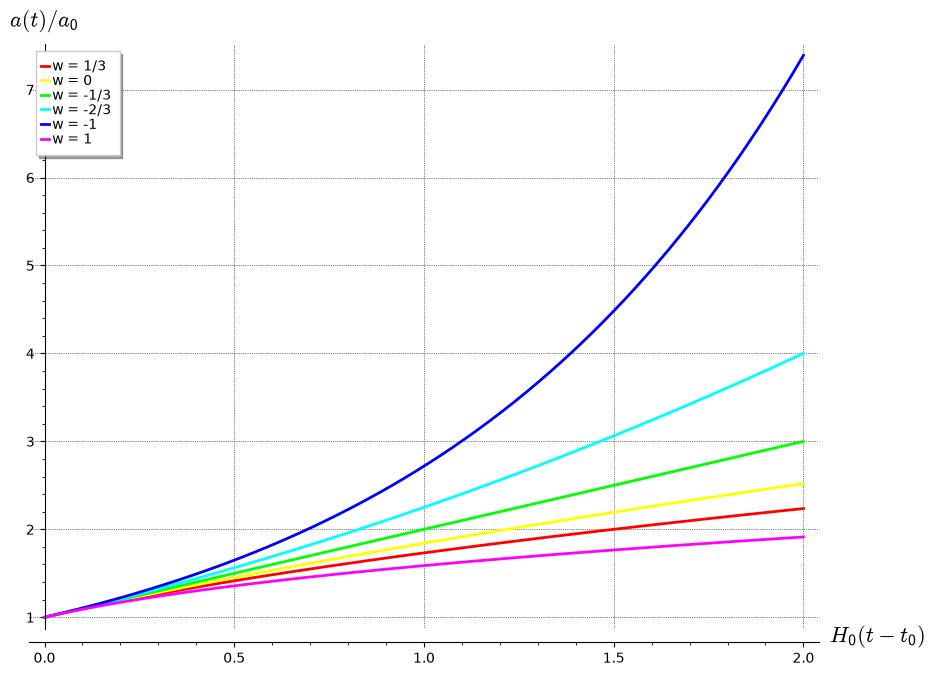

## Hubble parameter

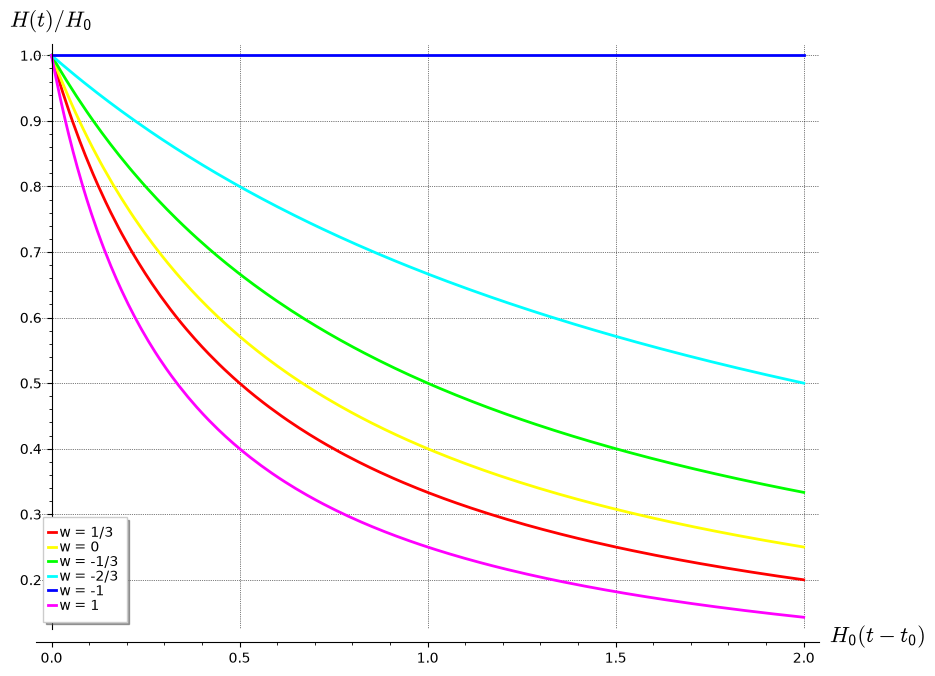

## Energy density

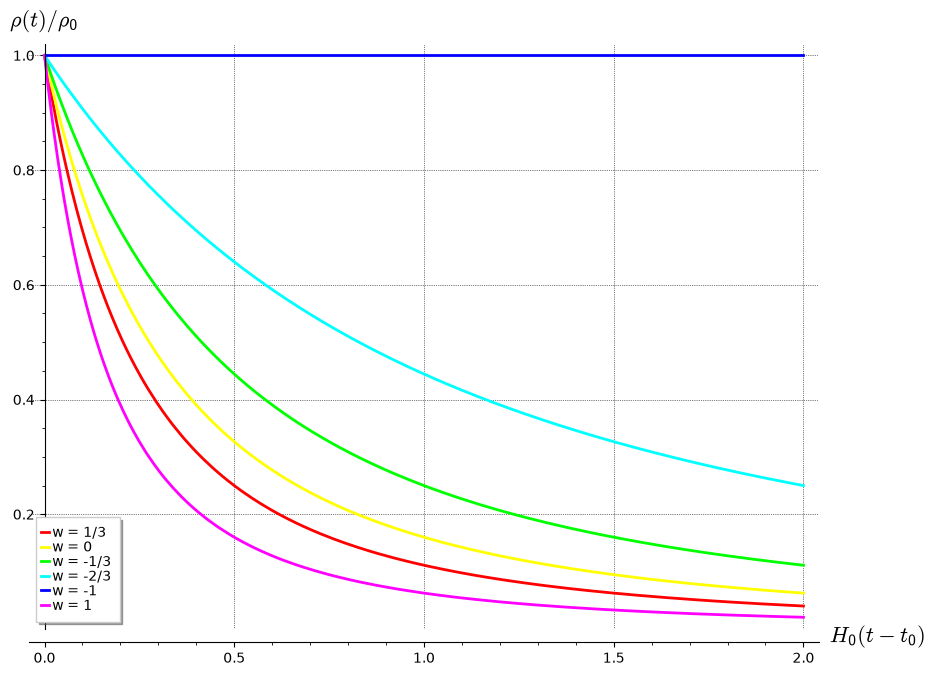

In [21]:

# ========================================
# COMPARISON OF FRIEDMANN SOLUTIONS
# ========================================

u = var('u')
colors = rainbow(len(fluids))

quantities = [
    ("Scale factor", 0, a0, r"a(t)/a_0"),
    ("Hubble parameter", 1, H0, r"H(t)/H_0"),
    ("Energy density", 2, rho0, r"\rho(t)/\rho_0")
]

for heading, index, norm, ylabel in quantities:

    display(Markdown("## " + heading))

    graph = Graphics()

    for i, (title, wi) in enumerate(fluids):

        solutions = friedmann_solution(wi)
        expression = solutions[index]/norm

        expression = expression.subs({
            t: u,
            t0: 0,
            H0: 1,
            a0: 1,
            rho0: 1
        }).simplify_full()

        graph += plot(
            expression,
            (u, 0, 2),
            color=colors[i],
            thickness=2,
            legend_label="w = " + str(wi)
        )

    graph.axes_labels([
        r"$H_0(t-t_0)$",
        "$" + ylabel + "$"
    ])

    show(graph, figsize=9, gridlines=True)


In [22]:

# =============================================
# PART 4 - FULL LAMBDA-CDM COSMOLOGY
# Symbolic calculations using SageMath
# =============================================

from IPython.display import display, Markdown, Math
%display latex

s, z_lcdm = var('s z_lcdm')
O_r, O_b, O_c, O_k, O_L = var(
    'O_r O_b O_c O_k O_L'
)
Hscale = var('Hscale')

O_m = O_b + O_c

# Dimensionless Hubble function E(a)^2
E2 = (
    O_r/s^4
    + O_b/s^3
    + O_c/s^3
    + O_k/s^2
    + O_L
)

# Deceleration parameter, derived from H(a)
q_model = (
    -1 - s*diff(E2, s)/(2*E2)
).simplify_full()

q_expected = (
    O_r/s^4 + O_m/(2*s^3) - O_L
)/E2

# Acceleration equation
acc_expected = -Hscale^2/2 * (
    2*O_r/s^4 + O_m/s^3 - 2*O_L
)

display(Markdown("# 4. The Lambda-CDM Model"))

display(Markdown("## 4.1 Cosmological components"))

display(Math(
    r"\begin{aligned}"
    r"p_r &= \frac{1}{3}\rho_r"
    r"\\[6pt]"
    r"p_b &= 0"
    r"\\[6pt]"
    r"p_{\mathrm{cdm}} &= 0"
    r"\\[6pt]"
    r"p_\Lambda &= -\rho_\Lambda"
    r"\end{aligned}"
))

display(Markdown("## 4.2 Energy conservation"))

display(Math(
    r"\begin{aligned}"
    r"\dot{\rho}_i+3H(1+w_i)\rho_i &= 0"
    r"\\[8pt]"
    r"\rho_r(a) &= \rho_{r,0}a^{-4}"
    r"\\[6pt]"
    r"\rho_b(a) &= \rho_{b,0}a^{-3}"
    r"\\[6pt]"
    r"\rho_{\mathrm{cdm}}(a) &= "
    r"\rho_{\mathrm{cdm},0}a^{-3}"
    r"\\[6pt]"
    r"\rho_\Lambda(a) &= \rho_{\Lambda,0}"
    r"\end{aligned}"
))

display(Markdown("## 4.3 First Friedmann equation"))

display(Math(
    r"\boxed{\begin{aligned}"
    r"H^2(a)=H_0^2\big["
    r"\Omega_{r,0}a^{-4}"
    r"+\Omega_{b,0}a^{-3}"
    r"+\Omega_{\mathrm{cdm},0}a^{-3}"
    r"+\Omega_{k,0}a^{-2}"
    r"+\Omega_{\Lambda,0}\big]"
    r"\end{aligned}}"
))

display(Markdown("## 4.4 Acceleration equation"))

display(Math(
    r"\boxed{\frac{\ddot a}{a}="
    r"-\frac{H_0^2}{2}\left["
    r"2\Omega_{r,0}a^{-4}"
    r"+(\Omega_{b,0}+\Omega_{\mathrm{cdm},0})a^{-3}"
    r"-2\Omega_{\Lambda,0}"
    r"\right]}"
))

display(Markdown("## 4.5 Hubble parameter as a function of redshift"))

display(Math(
    r"\boxed{H(z)=H_0\sqrt{"
    r"\Omega_{r,0}(1+z)^4"
    r"+(\Omega_{b,0}+\Omega_{\mathrm{cdm},0})(1+z)^3"
    r"+\Omega_{k,0}(1+z)^2"
    r"+\Omega_{\Lambda,0}}}"
))

display(Markdown("## 4.6 Deceleration parameter"))

display(Math(
    r"\boxed{q(a)=\frac{"
    r"\Omega_{r,0}a^{-4}"
    r"+\frac12(\Omega_{b,0}+\Omega_{\mathrm{cdm},0})a^{-3}"
    r"-\Omega_{\Lambda,0}"
    r"}{E^2(a)}}"
))

display(Markdown("## 4.7 Density parameters at any epoch"))

display(Math(
    r"\begin{aligned}"
    r"\Omega_r(a)&=\frac{\Omega_{r,0}a^{-4}}{E^2(a)}"
    r"\\[8pt]"
    r"\Omega_b(a)&=\frac{\Omega_{b,0}a^{-3}}{E^2(a)}"
    r"\\[8pt]"
    r"\Omega_{\mathrm{cdm}}(a)"
    r"&=\frac{\Omega_{\mathrm{cdm},0}a^{-3}}{E^2(a)}"
    r"\\[8pt]"
    r"\Omega_\Lambda(a)&=\frac{\Omega_{\Lambda,0}}{E^2(a)}"
    r"\\[8pt]"
    r"\Omega_k(a)&=\frac{\Omega_{k,0}a^{-2}}{E^2(a)}"
    r"\end{aligned}"
))

# Symbolic consistency checks
check1 = (
    E2.subs(s=1) - (O_r+O_b+O_c+O_k+O_L)
).simplify_full()

check2 = (q_model-q_expected).simplify_full()

check3 = (
    -Hscale^2*q_model*E2 - acc_expected
).simplify_full()

display(Markdown("## 4.8 Symbolic consistency checks"))
display(Math(
    r"\begin{aligned}"
    r"\Delta_{\mathrm{normalization}} &= "
    + latex(check1) +
    r"\\[6pt]"
    r"\Delta_q &= " + latex(check2) +
    r"\\[6pt]"
    r"\Delta_{\mathrm{acceleration}} &= "
    + latex(check3) +
    r"\end{aligned}"
))


# 4. The Lambda-CDM Model

## 4.1 Cosmological components

<IPython.core.display.Math object>

## 4.2 Energy conservation

<IPython.core.display.Math object>

...

<IPython.core.display.Math object>

## 4.7 Density parameters at any epoch

<IPython.core.display.Math object>

## 4.8 Symbolic consistency checks

<IPython.core.display.Math object>

## 4.9 Characteristic cosmic epochs

<IPython.core.display.Math object>

## 4.10 Hubble expansion history

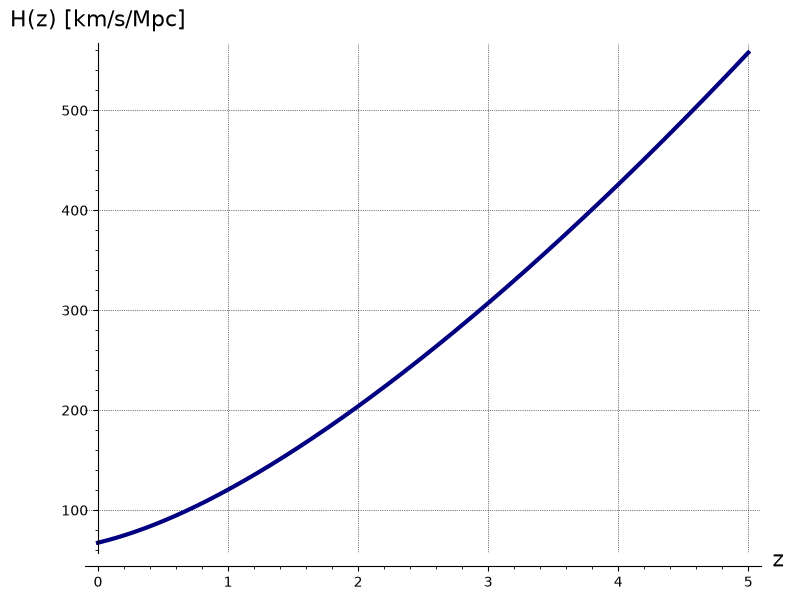

## 4.11 Deceleration history

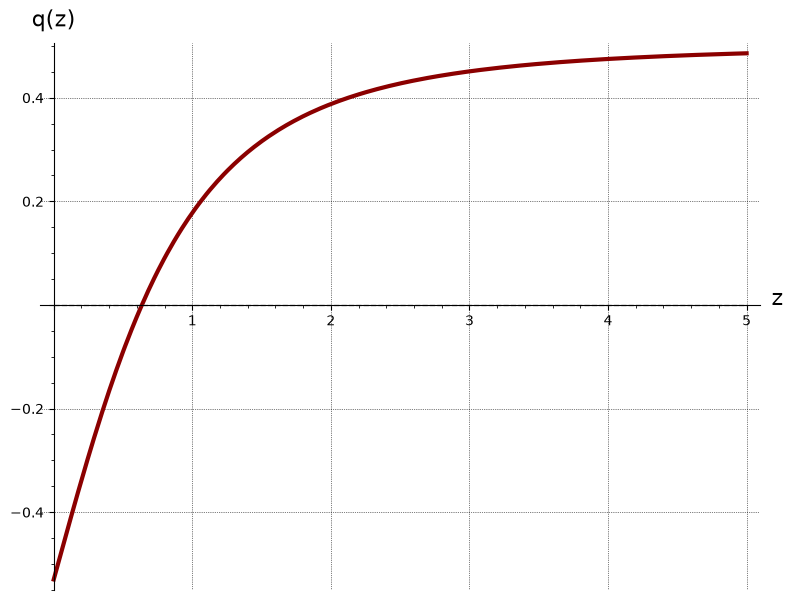

In [24]:

# ============================================
# NUMERICAL LAMBDA-CDM: COSMIC EVOLUTION
# ============================================

H0_num = 67.4

Or0 = 9.2e-5
Ob0 = 0.0493
Oc0 = 0.2640
Ok0 = 0.0
Om0 = Ob0 + Oc0
OL0 = 1.0 - Or0 - Om0 - Ok0

params = {
    O_r: Or0,
    O_b: Ob0,
    O_c: Oc0,
    O_k: Ok0,
    O_L: OL0
}

E2_num = E2.subs(params)
q_num = q_expected.subs(params)

# Equality of radiation and matter densities
a_rm = Or0/Om0
z_rm = 1/a_rm - 1

# Equality of matter and vacuum energy densities
a_mL = (Om0/OL0)^(1/3)
z_mL = 1/a_mL - 1

# Transition from deceleration to acceleration
a_acc = find_root(q_num, 0.3, 1.2)
z_acc = 1/a_acc - 1

# Cosmic age by numerical integration
# 1 Mpc = 3.085677581491367e19 km
# 1 Gyr = 3.15576e16 s
hubble_time_Gyr = (
    3.085677581491367e19
    / (H0_num*3.15576e16)
)

integral_result = numerical_integral(
    1/(s*sqrt(E2_num)), 1e-8, 1
)

age_Gyr = hubble_time_Gyr*integral_result[0]

display(Markdown("## 4.9 Characteristic cosmic epochs"))

display(Math(
    r"\begin{aligned}"
    r"\Omega_{\Lambda,0} &= " + f"{OL0:.6f}" +
    r"\\[8pt]"
    r"z_{\mathrm{rad-matter}} &= " + f"{z_rm:.1f}" +
    r"\\[8pt]"
    r"z_{\mathrm{matter-\Lambda}} &= " + f"{z_mL:.3f}" +
    r"\\[8pt]"
    r"z_{\mathrm{acceleration}} &= " + f"{z_acc:.3f}" +
    r"\\[8pt]"
    r"t_{\mathrm{Universe}} &= "
    + f"{age_Gyr:.3f}" + r"\ \mathrm{Gyr}"
    r"\end{aligned}"
))

# H(z) and q(z)
H_z = H0_num*sqrt(
    E2_num.subs(s=1/(1+z_lcdm))
)

q_z = q_num.subs(s=1/(1+z_lcdm))

display(Markdown("## 4.10 Hubble expansion history"))

p1 = plot(
    H_z, (z_lcdm, 0, 5),
    color='navy',
    thickness=3,
    axes_labels=['z', 'H(z) [km/s/Mpc]'],
    gridlines=True
)
show(p1, figsize=8)

display(Markdown("## 4.11 Deceleration history"))

p2 = plot(
    q_z, (z_lcdm, 0, 5),
    color='darkred',
    thickness=3,
    axes_labels=['z', 'q(z)'],
    gridlines=True
)

p2 += line(
    [(0,0),(5,0)],
    color='gray',
    linestyle='--'
)

show(p2, figsize=8)
